# Étape 6 : les expositions aux facteurs sont-elles stables dans le temps ?

À l'étape 4, la régression était estimée une seule fois sur 2000-2026 : elle suppose que les expositions (les bêtas) sont constantes sur 26 ans. Ici, on ré-estime la même régression sur des périodes et des régimes de marché distincts, puis on teste si les écarts entre estimations dépassent ce que le simple bruit statistique produirait.

Trois angles :
1. **Quatre sous-périodes** chronologiques, chacune marquée par un contexte de marché.
2. **Deux régimes de volatilité** : mois calmes et mois agités.
3. **Bêtas glissants sur 36 mois**, comparés à ce qu'on observerait si les vrais bêtas étaient constants.

In [1]:
import io
import zipfile
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import matplotlib.dates as mdates

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 130)
rng = np.random.default_rng(2026)

## 1. Données

Mêmes données qu'aux étapes 4 et 5 : facteurs de Kenneth French et cours mensuels ajustés, de janvier 2000 à août 2026 (320 mois). Les cibles sont les rendements excédentaires ($R - R_f$, en %) d'Apple et du portefeuille équipondéré de 107 grandes capitalisations américaines.

In [2]:
def lire_bloc_mensuel(chemin_zip):
    # Lit le premier bloc de données (mensuel) d'un CSV de Kenneth French.
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float)


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
FACTEURS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]

cours = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)
cours.index = pd.PeriodIndex(cours.index.astype(str).str[:7], freq="M")
cours = cours.sort_index()
cours = cours[~cours.index.duplicated(keep="last")]
rendements = 100 * cours.pct_change(fill_method=None)

sys.path.insert(0, str(ROOT / "scripts"))
from univers import PORTEFEUILLE

DEBUT, FIN = pd.Period("2000-01", "M"), min(facteurs.index.max(), rendements.index.max())
periode = pd.period_range(DEBUT, FIN, freq="M")
candidats = [t for liste in PORTEFEUILLE.values() for t in liste]
disponibles = [t for t in candidats if t in rendements.columns
               and rendements.loc[periode, t].notna().all()]

F = facteurs.loc[periode]
R = rendements.loc[periode]
CIBLES = ["Apple (AAPL)", "Portefeuille diversifié"]
Y = pd.DataFrame({
    "Apple (AAPL)": R["AAPL"],
    "Portefeuille diversifié": R[disponibles].mean(axis=1),
}).sub(F["RF"], axis=0)
T = len(periode)
print(f"{DEBUT} -> {FIN} : {T} mois, portefeuille de {len(disponibles)} titres")

2000-01 -> 2026-08 : 320 mois, portefeuille de 107 titres


## 2. Découpage en périodes et en régimes

### Quatre sous-périodes

| Période | Contexte |
|---|---|
| 2000-2006 | éclatement de la bulle internet, puis reprise |
| 2007-2012 | crise financière, puis crise des dettes souveraines en zone euro |
| 2013-2019 | expansion longue et peu volatile, taux bas |
| 2020-2026 | Covid, inflation et hausse des taux, essor de l'IA |

Chaque période compte 72 à 84 mois, soit plus de dix observations par coefficient estimé (7 coefficients).

### Deux régimes de volatilité

Pour chaque mois, on calcule la volatilité du facteur marché sur les **12 mois précédents** (sans le mois courant). Le mois est classé en « volatilité forte » si elle dépasse sa médiane sur 2000-2026, en « volatilité faible » sinon. Ce découpage regroupe des mois éloignés dans le temps mais semblables par le climat de marché, et donne deux échantillons de 160 mois.

In [3]:
PERIODES = {
    "2000-2006": ("2000-01", "2006-12"),
    "2007-2012": ("2007-01", "2012-12"),
    "2013-2019": ("2013-01", "2019-12"),
    "2020-2026": ("2020-01", str(FIN)),
}
periode_de = pd.Series(index=F.index, dtype=object)
for nom, (a, b) in PERIODES.items():
    periode_de.loc[a:b] = nom

# volatilité du marché sur les 12 mois précédents, en % annualisé
vol_passee = np.sqrt(12) * facteurs["Mkt-RF"].rolling(12).std().shift(1).loc[periode]
regime = pd.Series(np.where(vol_passee > vol_passee.median(), "volatilité forte", "volatilité faible"),
                   index=F.index)
print(f"Médiane de la volatilité passée du marché : {vol_passee.median():.1f} % par an")
pd.crosstab(periode_de, regime)

Médiane de la volatilité passée du marché : 14.1 % par an


col_0,volatilité faible,volatilité forte
row_0,,
2000-2006,37,47
2007-2012,26,46
2013-2019,66,18
2020-2026,31,49


## 3. Régressions par période et par régime

Même modèle et même estimation qu'à l'étape 4 : moindres carrés ordinaires, erreurs standard de Newey-West (6 retards).

In [4]:
def regression(y, X, retards=6):
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": retards})


def estimer(cible, masque):
    return regression(Y.loc[masque, cible], F.loc[masque, FACTEURS])


ECHANTILLONS = {"2000-2026": pd.Series(True, index=F.index)}
ECHANTILLONS.update({p: periode_de == p for p in PERIODES})
ECHANTILLONS.update({r: regime == r for r in ["volatilité faible", "volatilité forte"]})

estimations = {(c, e): estimer(c, m) for c in CIBLES for e, m in ECHANTILLONS.items()}


def tableau(cible):
    lignes = {}
    for e in ECHANTILLONS:
        res = estimations[(cible, e)]
        lignes[e] = pd.concat([res.params[FACTEURS],
                               pd.Series({"alpha annualisé (%)": 12 * res.params["const"],
                                          "R²": res.rsquared, "mois": int(res.nobs)})])
    return pd.DataFrame(lignes)


for c in CIBLES:
    print(f"\n=== {c} ===")
    display(tableau(c).round(2))


=== Apple (AAPL) ===


,2000-2026,2000-2006,2007-2012,2013-2019,2020-2026,volatilité faible,volatilité forte
Mkt-RF,1.21,1.37,1.47,1.01,1.12,1.45,1.15
SMB,0.25,0.68,-0.02,0.04,-0.15,-0.10,0.34
HML,-0.57,0.25,-0.98,-0.06,-0.59,-0.08,-0.69
RMW,0.25,0.02,0.06,1.77,0.28,0.95,0.13
CMA,-0.67,-2.15,-0.99,-1.93,0.32,-0.82,-0.56
Mom,-0.03,-0.03,0.02,-0.09,-0.19,0.37,-0.11
alpha annualisé (%),20.89,42.28,30.28,4.82,9.55,18.93,17.14
R²,0.37,0.40,0.50,0.45,0.59,0.31,0.45
mois,320.00,84.00,72.00,84.00,80.00,160.00,160.00



=== Portefeuille diversifié ===


,2000-2026,2000-2006,2007-2012,2013-2019,2020-2026,volatilité faible,volatilité forte
Mkt-RF,0.91,0.95,0.93,0.97,0.88,0.92,0.89
SMB,-0.02,0.01,-0.08,-0.04,0.04,0.04,-0.04
HML,0.19,0.15,0.18,-0.03,0.26,0.15,0.21
RMW,0.15,0.23,0.12,0.07,0.12,0.19,0.13
CMA,0.25,0.26,0.04,0.36,0.30,0.28,0.27
Mom,-0.06,-0.10,-0.06,-0.01,-0.05,-0.01,-0.09
alpha annualisé (%),2.89,4.02,4.65,2.06,0.22,3.19,2.63
R²,0.94,0.93,0.98,0.97,0.93,0.90,0.96
mois,320.00,84.00,72.00,84.00,80.00,160.00,160.00


## 4. Les écarts sont-ils significatifs ?

Des estimations sur 80 mois varient forcément un peu d'une période à l'autre, même si les vraies expositions ne bougent pas. Pour savoir si les écarts sont réels, on estime un seul modèle sur 2000-2026 dans lequel chaque coefficient peut changer selon la période :

$$y_t = \sum_{p} \mathbb{1}_{t \in p}\Big(\alpha_p + \sum_k b_{k,p}\,F_{k,t}\Big) + \varepsilon_t$$

puis on teste l'égalité des coefficients entre périodes (test de Wald, erreurs standard de Newey-West). C'est le test de Chow, rendu robuste à l'hétéroscédasticité et à l'autocorrélation.

- **Test joint** : les six expositions sont-elles les mêmes dans toutes les périodes ?
- **Test facteur par facteur** : l'exposition au facteur $k$ est-elle la même dans toutes les périodes ?

Même démarche pour les deux régimes de volatilité.

In [5]:
def test_stabilite(cible, groupes):
    # Régression avec interactions groupe x facteur, puis tests de Wald d'égalité.
    niveaux = list(pd.unique(groupes))
    base, autres = niveaux[0], niveaux[1:]
    X = F[FACTEURS].copy()
    for g in autres:
        ind = (groupes == g).astype(float)
        X[f"const|{g}"] = ind
        for f in FACTEURS:
            X[f"{f}|{g}"] = F[f] * ind
    res = regression(Y[cible], X)
    noms = res.params.index

    def p_valeur(prefixes):
        R = np.array([[1.0 if n == f"{p}|{g}" else 0.0 for n in noms] for p in prefixes for g in autres])
        return res.wald_test(R, scalar=True).pvalue

    sortie = {"toutes les expositions": p_valeur(FACTEURS)}
    sortie.update({f: p_valeur([f]) for f in FACTEURS})
    return pd.Series(sortie)


tests = pd.DataFrame({
    (c, d): test_stabilite(c, g)
    for c in CIBLES for d, g in [("4 périodes", periode_de), ("2 régimes de volatilité", regime)]
})
tests.index.name = "p-valeur du test d'égalité"
tests.map(lambda v: f"{v:.4f}")

Apple (AAPL)                         Portefeuille diversifié                        
                             4 périodes 2 régimes de volatilité              4 périodes 2 régimes de volatilité
p-valeur du test d'égalité                                                                                     
toutes les expositions           0.0000                  0.0482                  0.0000                  0.0083
Mkt-RF                           0.4738                  0.4094                  0.0491                  0.3590
SMB                              0.3389                  0.2324                  0.3385                  0.0725
HML                              0.0961                  0.1450                  0.0000                  0.4525
RMW                              0.0112                  0.0120                  0.1711                  0.3191
CMA                              0.0000                  0.6456                  0.0003                  0.8872
Mom                              0.8646                  0.1264                  0.0362                  0.0116

## 5. L'instabilité compte-t-elle en pratique ?

Un écart peut être statistiquement significatif et économiquement négligeable. On compare deux façons d'expliquer le rendement :
- **bêtas constants** : les coefficients estimés une fois sur 2000-2026 ;
- **bêtas par période** : les coefficients ré-estimés dans chacune des quatre périodes.

La mesure est la volatilité annualisée de la partie non expliquée (l'écart de suivi). Si elle baisse nettement avec les bêtas par période, l'instabilité a un coût réel pour qui suppose les bêtas fixes.

Le modèle par période a 28 coefficients contre 7 : il colle forcément mieux aux données. Pour comparer à armes égales, on corrige du nombre de coefficients, comme pour le $R^2$ ajusté : $\hat\sigma = \sqrt{\sum_t \hat\varepsilon_t^2 / (T - k)}$, avec $k = 7$ ou $k = 28$.

In [6]:
def ecart_de_suivi(cible, par_periode):
    residus = []
    for p in PERIODES:
        m = periode_de == p
        res = estimations[(cible, p)] if par_periode else estimations[(cible, "2000-2026")]
        X = sm.add_constant(F.loc[m, FACTEURS], has_constant="add")
        residus.append(Y.loc[m, cible] - X @ res.params)
    residus = pd.concat(residus)
    k = 7 * len(PERIODES) if par_periode else 7
    return np.sqrt(12) * np.sqrt((residus ** 2).sum() / (len(residus) - k))


importance = pd.DataFrame({
    c: {"volatilité du rendement (%)": np.sqrt(12) * Y[c].std(),
        "écart de suivi, bêtas constants (%)": ecart_de_suivi(c, False),
        "écart de suivi, bêtas par période (%)": ecart_de_suivi(c, True)}
    for c in CIBLES
}).T
importance["baisse de l'écart de suivi (%)"] = 100 * (
    1 - importance["écart de suivi, bêtas par période (%)"] / importance["écart de suivi, bêtas constants (%)"])
importance.round(2)

,volatilité du rendement (%),"écart de suivi, bêtas constants (%)","écart de suivi, bêtas par période (%)",baisse de l'écart de suivi (%)
Apple (AAPL),37.50,30.06,29.00,3.52
Portefeuille diversifié,14.78,3.69,3.42,7.43


## 6. Bêtas glissants et bruit d'estimation

On ré-estime la régression sur chaque fenêtre de 36 mois, en avançant d'un mois à la fois. Les bêtas glissants bougent toujours un peu, ne serait-ce qu'à cause du bruit d'estimation sur 36 mois.

Pour séparer le bruit de la vraie variation, on construit une **bande de référence** par simulation :
1. on part des bêtas estimés sur 2000-2026, supposés constants ;
2. on fabrique 500 historiques artificiels $y^*_t = \hat\alpha + \sum_k \hat b_k F_{k,t} + \varepsilon^*_t$, où les $\varepsilon^*$ sont tirés par blocs de 12 mois consécutifs parmi les vrais résidus (pour garder leur volatilité variable et leur autocorrélation) ;
3. on calcule les bêtas glissants sur chaque historique artificiel.

La bande grise contient 90 % des bêtas glissants obtenus **si les vrais bêtas étaient constants**. Un bêta observé qui en sort souvent, ou longtemps, varie vraiment dans le temps.

In [7]:
FENETRE = 36
N_SIMULATIONS = 500
TAILLE_BLOC = 12


def betas_glissants(y, X):
    Xc = np.column_stack([np.ones(len(X)), X])
    sortie = np.full((len(y), X.shape[1]), np.nan)
    for fin in range(FENETRE, len(y) + 1):
        b, *_ = np.linalg.lstsq(Xc[fin - FENETRE:fin], y[fin - FENETRE:fin], rcond=None)
        sortie[fin - 1] = b[1:]
    return sortie


def tirage_par_blocs(residus):
    n = len(residus)
    debuts = rng.integers(0, n - TAILLE_BLOC + 1, size=n // TAILLE_BLOC + 1)
    return np.concatenate([residus[d:d + TAILLE_BLOC] for d in debuts])[:n]


X = F[FACTEURS].values
glissants, bandes, hors_bande = {}, {}, {}
for c in CIBLES:
    res = estimations[(c, "2000-2026")]
    y = Y[c].values
    ajuste = res.fittedvalues.values
    resid = res.resid.values
    glissants[c] = pd.DataFrame(betas_glissants(y, X), index=F.index, columns=FACTEURS)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # fenêtres incomplètes du début : NaN attendus
        sims = np.array([betas_glissants(ajuste + tirage_par_blocs(resid), X) for _ in range(N_SIMULATIONS)])
        bandes[c] = (pd.DataFrame(np.nanquantile(sims, 0.05, axis=0), index=F.index, columns=FACTEURS),
                     pd.DataFrame(np.nanquantile(sims, 0.95, axis=0), index=F.index, columns=FACTEURS))
    obs = glissants[c].dropna()
    dehors = (obs < bandes[c][0].loc[obs.index]) | (obs > bandes[c][1].loc[obs.index])
    hors_bande[c] = dehors.mean()
    # Les fenêtres se chevauchent : la part hors bande varie beaucoup même avec des bêtas constants.
    # On la compare donc à sa distribution dans les simulations.
    m = ~np.isnan(glissants[c].values[:, 0])
    parts_sim = np.array([((s[m] < bandes[c][0].values[m]) | (s[m] > bandes[c][1].values[m])).mean(axis=0) for s in sims])
    hors_bande[(c, "95e centile simulé")] = pd.Series(np.quantile(parts_sim, 0.95, axis=0), index=FACTEURS)
    hors_bande[(c, "p-valeur")] = pd.Series((parts_sim >= dehors.mean().values).mean(axis=0), index=FACTEURS)

hors_bande = pd.DataFrame({(k if isinstance(k, tuple) else (k, "part observée")): v for k, v in hors_bande.items()})
hors_bande.index.name = "mois hors de la bande à 90 % (10 % attendus en moyenne si bêtas constants)"
hors_bande.round(3)

Apple (AAPL)                             Portefeuille diversifié  \
                                                   part observée 95e centile simulé p-valeur           part observée   
mois hors de la bande à 90 % (10 % attendus en ...                                                                     
Mkt-RF                                                     0.130              0.249    0.318                   0.042   
SMB                                                        0.158              0.239    0.202                   0.049   
HML                                                        0.095              0.228    0.498                   0.400   
RMW                                                        0.123              0.239    0.356                   0.039   
CMA                                                        0.225              0.218    0.046                   0.151   
Mom                                                        0.070              0.235    0.606                   0.091   

                                                                                
                                                   95e centile simulé p-valeur  
mois hors de la bande à 90 % (10 % attendus en ...                              
Mkt-RF                                                          0.225    0.776  
SMB                                                             0.249    0.734  
HML                                                             0.235    0.000  
RMW                                                             0.232    0.790  
CMA                                                             0.232    0.202  
Mom                                                             0.246    0.492

In [8]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS_BANDE = "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")

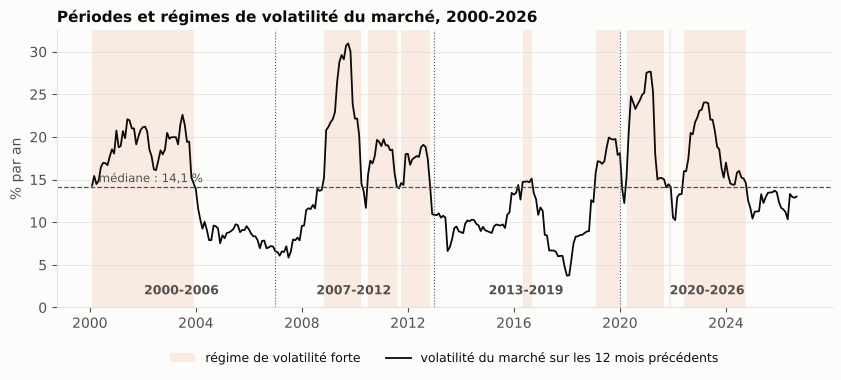

In [9]:
# Volatilité passée du marché, régimes et sous-périodes
fig, ax = plt.subplots(figsize=(10, 3.6))
dates = vol_passee.index.to_timestamp(how="end")
ax.fill_between(dates, 0, vol_passee.max() * 1.05, where=(regime == "volatilité forte").values,
                color=ORANGE, alpha=0.12, lw=0, step="mid", label="régime de volatilité forte")
ax.plot(dates, vol_passee, color=TEXTE, lw=1.3, label="volatilité du marché sur les 12 mois précédents")
ax.axhline(vol_passee.median(), color=TEXTE2, lw=0.9, ls="--")
ax.text(dates[3], vol_passee.median() + 0.6, f"médiane : {vol_passee.median():.1f} %".replace(".", ","),
        color=TEXTE2, fontsize=8.5)
for nom, (a, b) in list(PERIODES.items())[1:]:
    ax.axvline(pd.Period(a, "M").to_timestamp(), color=TEXTE2, lw=0.8, ls=":")
for nom, (a, b) in PERIODES.items():
    milieu = pd.Period(a, "M").to_timestamp() + (pd.Period(b, "M").to_timestamp() - pd.Period(a, "M").to_timestamp()) / 2
    ax.text(milieu, 1.2, nom, ha="center", va="bottom", fontsize=9, color=TEXTE2, fontweight="bold")
ax.set_ylim(0, vol_passee.max() * 1.05)
ax.set_ylabel("% par an")
ax.set_title("Périodes et régimes de volatilité du marché, 2000-2026")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
ax.grid(axis="x", visible=False)
sauver(fig, "regimes_volatilite_marche.png")
plt.show()

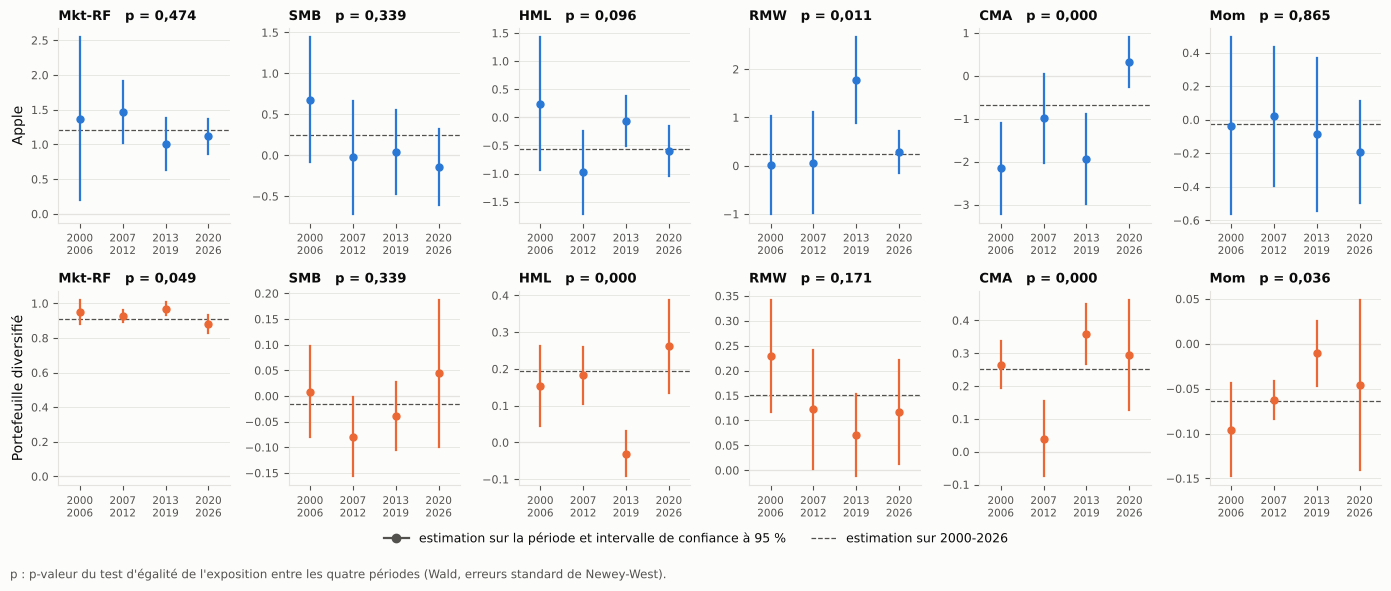

In [10]:
# Expositions par sous-période, avec intervalle de confiance à 95 %
fig, axes = plt.subplots(2, 6, figsize=(14, 5.4))
noms_p = list(PERIODES)
for ligne, (c, col) in enumerate(zip(CIBLES, [BLEU, ORANGE])):
    for j, f in enumerate(FACTEURS):
        ax = axes[ligne, j]
        tout = estimations[(c, "2000-2026")].params[f]
        ax.axhline(tout, color=TEXTE2, lw=0.9, ls="--")
        ax.axhline(0, color=GRILLE, lw=0.9)
        for i, p in enumerate(noms_p):
            res = estimations[(c, p)]
            b = res.params[f]
            bas, haut = res.conf_int().loc[f]
            ax.plot([i, i], [bas, haut], color=col, lw=1.6)
            ax.plot(i, b, "o", color=col, ms=5)
        ax.set_xticks(range(len(noms_p)), [p.replace("-", "\n") for p in noms_p], fontsize=7.5)
        ax.set_xlim(-0.5, len(noms_p) - 0.5)
        ax.tick_params(axis="y", labelsize=8)
        ax.grid(axis="x", visible=False)
        p_val = tests.loc[f, (c, "4 périodes")]
        ax.set_title(f"{f}   p = {p_val:.3f}".replace(".", ","), fontsize=9.5)
    axes[ligne, 0].set_ylabel(c.split(" (")[0], fontsize=10, color=TEXTE)
poignees = [plt.Line2D([], [], color=TEXTE2, marker="o", lw=1.6),
            plt.Line2D([], [], color=TEXTE2, lw=0.9, ls="--")]
fig.legend(poignees, ["estimation sur la période et intervalle de confiance à 95 %", "estimation sur 2000-2026"],
           ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.04), fontsize=9)
fig.text(0.01, -0.08, "p : p-valeur du test d'égalité de l'exposition entre les quatre périodes "
         "(Wald, erreurs standard de Newey-West).", fontsize=8.5, color=TEXTE2)
fig.tight_layout()
sauver(fig, "regimes_expositions_periodes.png")
plt.show()

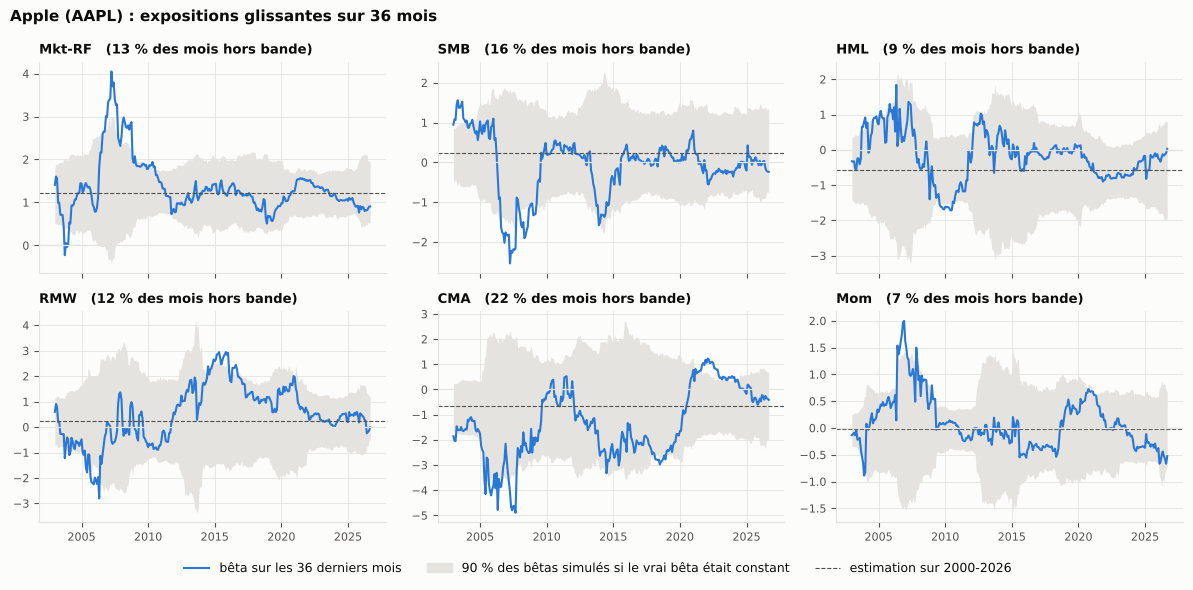

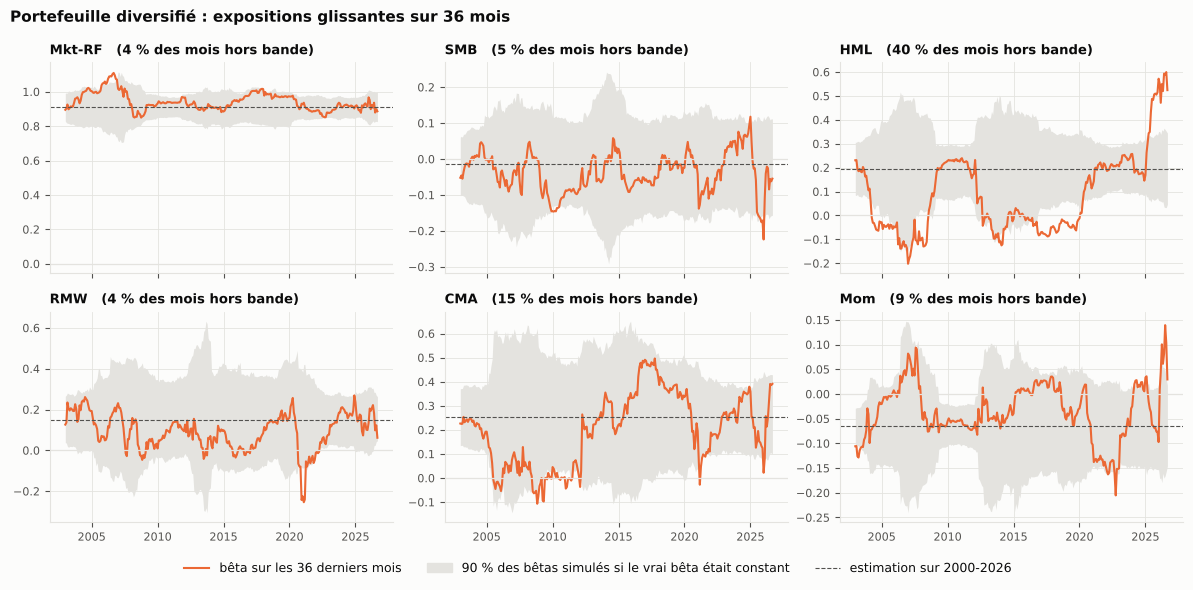

In [11]:
# Bêtas glissants sur 36 mois et bande à 90 % sous l'hypothèse de bêtas constants
for c, col, nom_fichier in [(CIBLES[0], BLEU, "regimes_betas_glissants_apple.png"),
                            (CIBLES[1], ORANGE, "regimes_betas_glissants_portefeuille.png")]:
    fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharex=True)
    dates = F.index.to_timestamp(how="end")
    bas, haut = bandes[c]
    for ax, f in zip(axes.ravel(), FACTEURS):
        ax.fill_between(dates, bas[f], haut[f], color=GRIS_BANDE, lw=0)
        ax.plot(dates, glissants[c][f], color=col, lw=1.5)
        ax.axhline(estimations[(c, "2000-2026")].params[f], color=TEXTE2, lw=0.8, ls="--")
        ax.axhline(0, color=GRILLE, lw=0.9)
        ax.set_title(f"{f}   ({100 * hors_bande.loc[f, (c, 'part observée')]:.0f} % des mois hors bande)", fontsize=9.5)
        ax.tick_params(labelsize=8)
        ax.xaxis.set_major_locator(mdates.YearLocator(5))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    poignees = [plt.Line2D([], [], color=col, lw=1.5), plt.Rectangle((0, 0), 1, 1, color=GRIS_BANDE),
                plt.Line2D([], [], color=TEXTE2, lw=0.8, ls="--")]
    fig.legend(poignees, ["bêta sur les 36 derniers mois", "90 % des bêtas simulés si le vrai bêta était constant",
                          "estimation sur 2000-2026"], ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.05),
               fontsize=9)
    fig.suptitle(f"{c} : expositions glissantes sur 36 mois", x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout()
    sauver(fig, nom_fichier)
    plt.show()